In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error , mean_squared_error, r2_score
from  scipy import stats 

sns.set_style("whitegrid")
pd.set_option("display.max_columns",50)
pd.set_option("display.float_format","{:.2f}".format)
print("Libraries loaded.")

Libraries loaded.


In [2]:
df_raw = pd.read_csv(r"C:\Users\Admin\Downloads\bikes (1).csv")


In [3]:
df_raw

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011,7000 Km,first owner,agra,\n\n 42 kmpl,16 bhp,55000
7853,Bajaj Discover 100cc 2015,2015,Mileage 80 Kmpl,first owner,delhi,\n\n 80 Kmpl,7.7,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407 Km,first owner,bangalore,\n\n 65 kmpl,17 bhp,61740
7855,Bajaj V15 150cc 2016,2016,7524 Km,first owner,bangalore,\n\n 57 kmpl,11.80 bhp,49000


In [4]:
df_raw.head()

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500


In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   model_name  7857 non-null   str  
 1   model_year  7857 non-null   int64
 2   kms_driven  7857 non-null   str  
 3   owner       7857 non-null   str  
 4   location    7838 non-null   str  
 5   mileage     7846 non-null   str  
 6   power       7826 non-null   str  
 7   price       7857 non-null   int64
dtypes: int64(2), str(6)
memory usage: 491.2 KB


In [6]:
df_raw['owner'].unique()

<StringArray>
['first owner', 'third owner', 'second owner', 'fourth owner or more']
Length: 4, dtype: str

In [7]:
df_raw['owner'].value_counts()

owner
first owner             6817
second owner             833
third owner              134
fourth owner or more      73
Name: count, dtype: int64

In [8]:
df_raw.dtypes

model_name      str
model_year    int64
kms_driven      str
owner           str
location        str
mileage         str
power           str
price         int64
dtype: object

In [9]:
df_raw.shape

(7857, 8)

In [10]:
df_raw.duplicated().sum()

np.int64(0)

In [11]:
df_raw.isnull().sum()

model_name     0
model_year     0
kms_driven     0
owner          0
location      19
mileage       11
power         31
price          0
dtype: int64

In [12]:
df_raw['price'].describe()

count      7857.00
mean     106791.34
std      138926.12
min           0.00
25%       42000.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [13]:
df_raw.columns

Index(['model_name', 'model_year', 'kms_driven', 'owner', 'location',
       'mileage', 'power', 'price'],
      dtype='str')

In [14]:
df_raw[[ 'kms_driven','mileage', 'power']]

,kms_driven,mileage,power
0,17000 Km,\n\n 35 kmpl,19 bhp
1,50000 Km,\n\n 35 kmpl,19.80 bhp
2,14795 Km,\n\n 30 kmpl,28 bhp
3,Mileage 28 Kms,\n\n 28 Kms,34.50 bhp
4,2000 Km,\n\n,30 bhp
...,...,...,...
7852,7000 Km,\n\n 42 kmpl,16 bhp
7853,Mileage 80 Kmpl,\n\n 80 Kmpl,7.7
7854,6407 Km,\n\n 65 kmpl,17 bhp
7855,7524 Km,\n\n 57 kmpl,11.80 bhp


In [15]:
def get_number(value):
    if pd.isna(value):
        return np.nan
    value = str(value).replace(',','')

    number=''
    dot_used = False

    for i in value:
        if i.isdigit():
            number+=i

        elif i=='.' and not dot_used:
            dot_used = True

        elif number:
            break

    return float(number) if number else np.nan

 

In [16]:
df_raw.columns

Index(['model_name', 'model_year', 'kms_driven', 'owner', 'location',
       'mileage', 'power', 'price'],
      dtype='str')

In [17]:
column_name = ['model_year', 'kms_driven','mileage', 'power', 'price']

In [18]:
column_name = ['model_year', 'kms_driven','mileage', 'power', 'price']

for i in column_name:
    df_raw[i] = df_raw[i].apply(get_number)

In [19]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   model_name  7857 non-null   str    
 1   model_year  7857 non-null   float64
 2   kms_driven  7854 non-null   float64
 3   owner       7857 non-null   str    
 4   location    7838 non-null   str    
 5   mileage     7083 non-null   float64
 6   power       7826 non-null   float64
 7   price       7857 non-null   float64
dtypes: float64(5), str(3)
memory usage: 491.2 KB


In [20]:
df_raw.duplicated().sum()

np.int64(0)

In [21]:
df_raw.dropna(subset = 'price')

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,1980.00,115000.00
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,3450.00,100000.00
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.00,7000.00,first owner,agra,42.00,16.00,55000.00
7853,Bajaj Discover 100cc 2015,2015.00,80.00,first owner,delhi,80.00,77.00,28000.00
7854,Bajaj Pulsar 180cc 2016,2016.00,6407.00,first owner,bangalore,65.00,17.00,61740.00
7855,Bajaj V15 150cc 2016,2016.00,7524.00,first owner,bangalore,57.00,1180.00,49000.00


In [22]:
df=df_raw.dropna(subset = 'price')

In [23]:
df

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,1980.00,115000.00
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,3450.00,100000.00
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.00,7000.00,first owner,agra,42.00,16.00,55000.00
7853,Bajaj Discover 100cc 2015,2015.00,80.00,first owner,delhi,80.00,77.00,28000.00
7854,Bajaj Pulsar 180cc 2016,2016.00,6407.00,first owner,bangalore,65.00,17.00,61740.00
7855,Bajaj V15 150cc 2016,2016.00,7524.00,first owner,bangalore,57.00,1180.00,49000.00


In [24]:
df=df[df['price']>0]

In [25]:
df['model_year']

0      2017.00
1      2016.00
2      2012.00
3      2017.00
4      2020.00
         ...  
7852   2011.00
7853   2015.00
7854   2016.00
7855   2016.00
7856   2016.00
Name: model_year, Length: 7826, dtype: float64

In [26]:
df[df['model_year']<1990]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
1691,Royal Enfield Bullet 350 cc 1982,1982.00,22000.00,first owner,pune,NaN,NaN,150000.00
1716,Royal Enfield Bullet 350 cc 1982,1982.00,16245.00,first owner,delhi,NaN,NaN,70000.00
2211,Bajaj Pulsar NS 200cc 2013,1950.00,35.00,first owner,noida,35.00,2319.00,55000.00
2487,Royal Enfield Bullet 350 cc 1982,1982.00,3000.00,second owner,lalitpur,NaN,NaN,130000.00
2638,Ideal Jawa Yezdi Delux 250 cc 1978,1978.00,85000.00,first owner,chikamaglur,NaN,NaN,100000.00
2714,Royal Enfield Bullet 350 cc 1982,1982.00,21000.00,first owner,nashik,NaN,NaN,170000.00
3088,Royal Enfield Bullet 350 cc 1982,1982.00,10000.00,first owner,mumbai,NaN,NaN,60000.00
3429,Royal Enfield‎ Bullet 350cc 1970,1970.00,5000.00,third owner,pune,25.00,1980.00,190000.00
4174,Royal Enfield Standard 350cc 1985,1985.00,40.00,third owner,kolhapur,40.00,18.00,125000.00
4258,Bajaj Pulsar NS 200cc 2013,1950.00,35.00,third owner,khalilabad,35.00,2319.00,55000.00


In [27]:
import warnings
warnings.filterwarnings('ignore')

In [28]:
pd.Timestamp.today()

Timestamp('2026-11-05 09:33:26.332643')

In [29]:
pd.Timestamp.today().year

2026

In [30]:
if 'model_year' in df.columns:
    current_year = pd.Timestamp.today().year
    df['model_year']= df['model_year'].between(1998,current_year)

In [31]:
df['model_year']

0       True
1       True
2       True
3       True
4       True
        ... 
7852    True
7853    True
7854    True
7855    True
7856    True
Name: model_year, Length: 7826, dtype: bool

In [32]:
df.describe

<bound method NDFrame.describe of                             model_name  model_year  kms_driven        owner  \
0        Bajaj Avenger Cruise 220 2017        True    17000.00  first owner   
1     Royal Enfield Classic 350cc 2016        True    50000.00  first owner   
2                  Hyosung GT250R 2012        True    14795.00  first owner   
3           Bajaj Dominar 400 ABS 2017        True       28.00  first owner   
4                Jawa Perak 330cc 2020        True     2000.00  first owner   
...                                ...         ...         ...          ...   
7852         Yamaha YZF-R15 150cc 2011        True     7000.00  first owner   
7853         Bajaj Discover 100cc 2015        True       80.00  first owner   
7854           Bajaj Pulsar 180cc 2016        True     6407.00  first owner   
7855              Bajaj V15 150cc 2016        True     7524.00  first owner   
7856           Bajaj Pulsar 220cc 2016        True    15000.00  first owner   

         location

In [33]:
df.dropna()

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000.00
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000.00
5,KTM Duke 200cc 2012,True,24561.00,third owner,bangalore,35.00,25.00,63400.00
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000.00
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000.00
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740.00
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000.00


In [34]:
df['price'].mean()

np.float64(107214.3539483772)

In [35]:
df['price'].max()

np.float64(3000000.0)

In [36]:
df['price'].min()

np.float64(2000.0)

In [37]:
df['price'].describe()

count      7826.00
mean     107214.35
std      139038.02
min        2000.00
25%       42500.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [38]:
df['location'].isnull

<bound method Series.isnull of 0         hyderabad
1         hyderabad
2         hyderabad
3       pondicherry
4         bangalore
           ...     
7852           agra
7853          delhi
7854      bangalore
7855      bangalore
7856        chennai
Name: location, Length: 7826, dtype: str>

In [39]:
for col in ['kms_driven', 'mileage','power']:
    if col in df.columns:
        df.loc[df[col]<0, col] = np.nan

In [40]:
df_clean =df.copy()
df_clean.to_csv('bikes_',index = False)

print('cleand dataset saved as bikes_cleaned.csv')
display(df_clean.head())

cleand dataset saved as bikes_cleaned.csv


,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000.00
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000.00
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500.00


In [41]:
if 'model_year' in df.columns:
    current_year =pd.Timestamp.today().year
    df['bike_age']= current_year - df['model_year']

In [42]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000.00
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000.00
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500.00
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000.00
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000.00
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740.00
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000.00


In [43]:
df_clean['price'].describe()

count      7826.00
mean     107214.35
std      139038.02
min        2000.00
25%       42500.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [44]:
df_clean['price'].skew

<bound method Series.skew of 0       63500.00
1      115000.00
2      300000.00
3      100000.00
4      197500.00
          ...   
7852    55000.00
7853    28000.00
7854    61740.00
7855    49000.00
7856    65000.00
Name: price, Length: 7826, dtype: float64>

In [45]:
df_clean['price'].dtypes

dtype('float64')

<Axes: xlabel='price', ylabel='Count'>

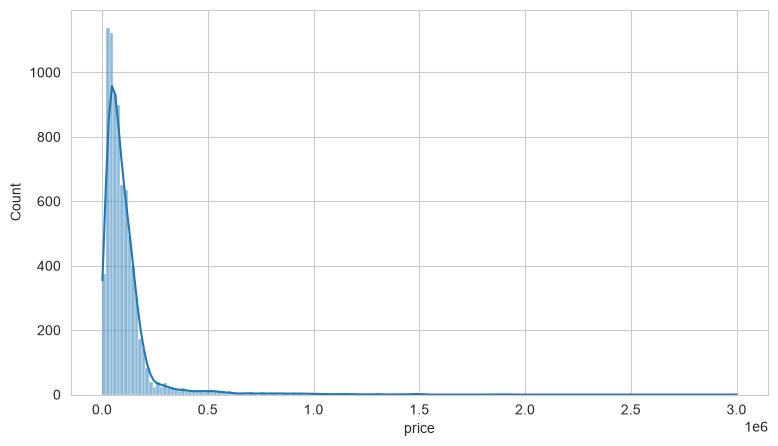

In [46]:
plt.figure(figsize=(9,5))
sns.histplot(data = df_clean , x='price',kde=True)


In [47]:
df_clean['model_name'].str.split()

0          [Bajaj, Avenger, Cruise, 220, 2017]
1       [Royal, Enfield, Classic, 350cc, 2016]
2                      [Hyosung, GT250R, 2012]
3             [Bajaj, Dominar, 400, ABS, 2017]
4                   [Jawa, Perak, 330cc, 2020]
                         ...                  
7852            [Yamaha, YZF-R15, 150cc, 2011]
7853            [Bajaj, Discover, 100cc, 2015]
7854              [Bajaj, Pulsar, 180cc, 2016]
7855                 [Bajaj, V15, 150cc, 2016]
7856              [Bajaj, Pulsar, 220cc, 2016]
Name: model_name, Length: 7826, dtype: object

In [48]:
df_clean['brand']= df_clean['model_name'].str.split().str[0]

In [49]:
df_clean['brand']

0         Bajaj
1         Royal
2       Hyosung
3         Bajaj
4          Jawa
         ...   
7852     Yamaha
7853      Bajaj
7854      Bajaj
7855      Bajaj
7856      Bajaj
Name: brand, Length: 7826, dtype: object

In [50]:
brand_stats=df_clean.groupby('brand')['price'].agg(['median','mean','count'])


In [51]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00,Bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000.00,Royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00,Hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000.00,Bajaj
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500.00,Jawa
...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000.00,Yamaha
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000.00,Bajaj
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740.00,Bajaj
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000.00,Bajaj


In [52]:
brand_stats[brand_stats['count']>10].sort_values(by='median', ascending = False).head(10)

,median,mean,count
brand,,,
Ducati,907293.50,976293.69,16
Triumph,800000.00,843183.25,36
Kawasaki,465000.00,496517.70,67
Harley-Davidson,450000.00,512722.60,171
Benelli,260000.00,301581.89,53
Husqvarna,205000.00,206767.00,11
Hyosung,198600.00,221660.19,52
Jawa,165000.00,171286.13,46
KTM,147000.00,150354.56,491


In [53]:
brand_top_10=brand_stats[brand_stats['count']>10].sort_values(by='median', ascending = False).head(10)

<Axes: xlabel='brand', ylabel='median'>

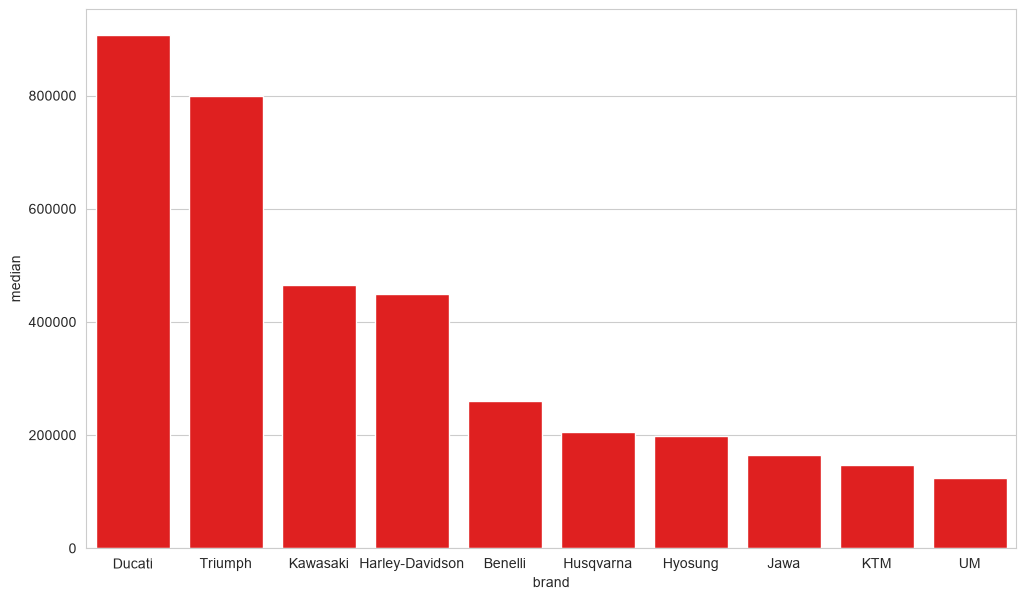

In [54]:
plt.figure(figsize=(12,7))
sns.barplot(data=brand_top_10 , x = 'brand' , y='median',color='red')

In [55]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00,Bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,1980.00,115000.00,Royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00,Hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,3450.00,100000.00,Bajaj
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500.00,Jawa
...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000.00,Yamaha
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,77.00,28000.00,Bajaj
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740.00,Bajaj
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,1180.00,49000.00,Bajaj


In [56]:
df_clean[['kms_driven','price']].corr()

,kms_driven,price
kms_driven,1.00,-0.11
price,-0.11,1.00


In [57]:
plot_data = df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
    plot_data = plot_data.sample(3000,random_state=42)



<Axes: xlabel='kms_driven', ylabel='price'>

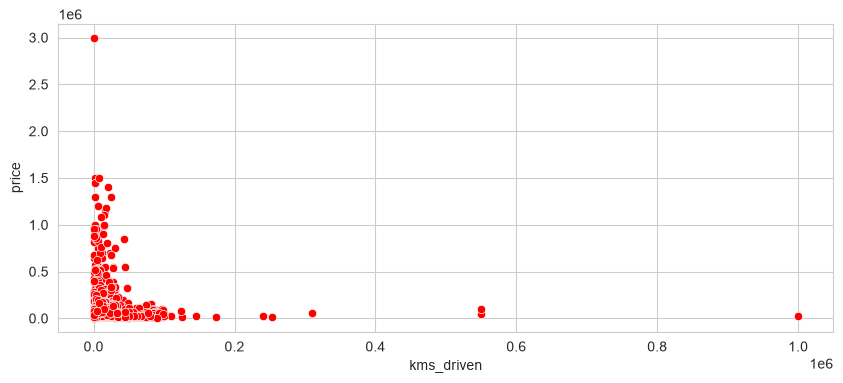

In [58]:
plt.figure(figsize=(10,4))

sns.scatterplot(data = plot_data , x='kms_driven', y='price',color='red')

<Axes: xlabel='kms_driven', ylabel='price'>

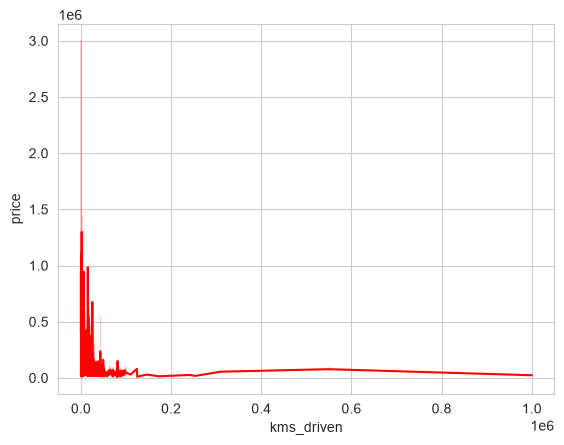

In [59]:
sns.lineplot(data = plot_data , x='kms_driven', y='price',color='red')

<Axes: xlabel='kms_driven', ylabel='price'>

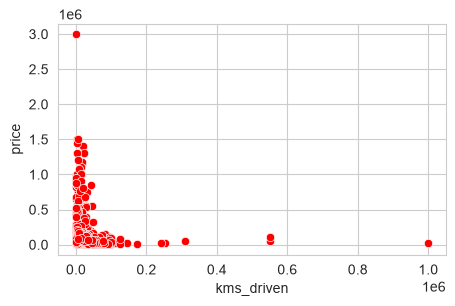

In [60]:
plot_data = df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
    plot_data = plot_data.sample(3000,random_state=42)
    
plt.figure(figsize=(5,3))

sns.scatterplot(data = plot_data , x='kms_driven', y='price',color='red')



<Axes: >

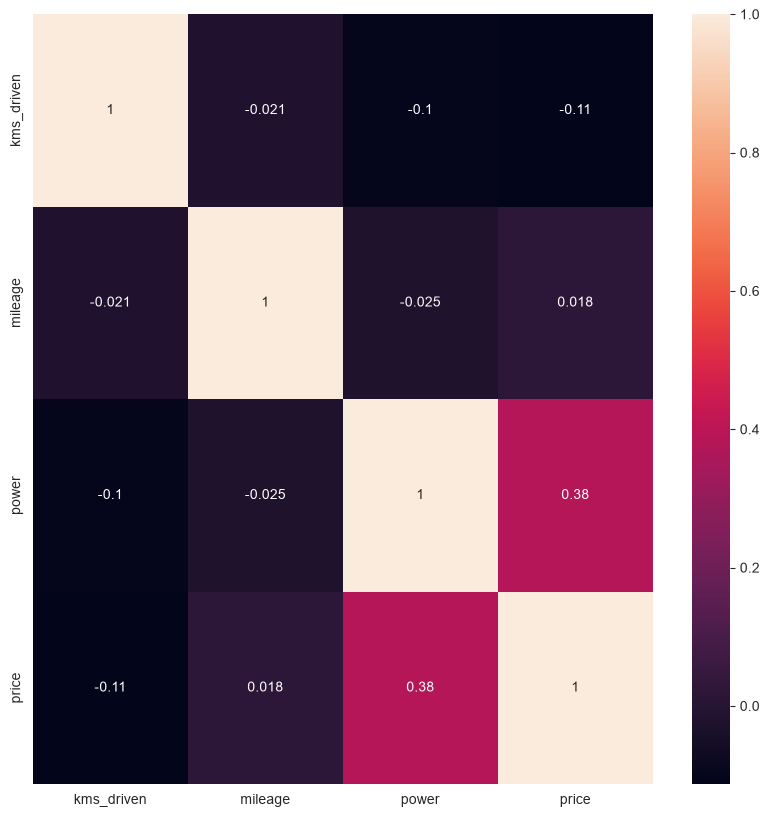

In [61]:
numeric_df= df_clean.select_dtypes(include='number')

plt.figure(figsize=(10,10))
sns.heatmap(numeric_df.corr(),annot=True)

In [62]:
df_clean.dropna(inplace=True)


In [63]:
df_clean.reset_index(inplace=True , drop='first')

In [64]:
data=df_clean.drop(['model_name','location'],axis=1)

In [65]:
data.columns

Index(['model_year', 'kms_driven', 'owner', 'mileage', 'power', 'price',
       'brand'],
      dtype='str')

In [66]:
x=data[[ 'model_year', 'kms_driven', 'owner', 'mileage', 'power',  'brand']]
y=data['price']

In [67]:
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x,y,random_state=42,test_size=0.2)

In [68]:
numerical_column=x.select_dtypes(include='number').columns.tolist()
categorical_column=x.select_dtypes(exclude='number').columns.tolist()

In [69]:
numeric_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))])
categorical_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore'))])


In [70]:
transformer = []
if numerical_column:
    transformer.append(('numeric',numeric_pipeline,numerical_column))
if categorical_column:
    transformer.append(('categorical', categorical_pipeline,categorical_column))

preprocessor = ColumnTransformer(transformers=transformer)

model= Pipeline(steps= [('preprocessor', preprocessor),('regression ', LinearRegression())])

model.fit(x_train, y_train)
print("Linear regression model trained")

Linear regression model trained


In [71]:
import numpy as np

In [72]:

y_pred = model.predict(x_test)

comparison = pd.DataFrame({
    "actual_price": y_test.values,
    "predicted_price": np.round(y_pred ,0),
    "error_actual_minus_predicted" : np.round(y_test.values - y_pred , 0)
})

comparison["absolute_error"] = comparison["error_actual_minus_predicted"].abs()

display(comparison.head(15))

,actual_price,predicted_price,error_actual_minus_predicted,absolute_error
0,36000.00,52932.00,-16932.00,16932.00
1,45000.00,42507.00,2493.00,2493.00
2,75000.00,94898.00,-19898.00,19898.00
3,510000.00,575584.00,-65584.00,65584.00
4,130000.00,125129.00,4871.00,4871.00
5,52400.00,91732.00,-39332.00,39332.00
6,198000.00,142392.00,55608.00,55608.00
7,50175.00,103452.00,-53277.00,53277.00
8,44000.00,71882.00,-27882.00,27882.00
9,61000.00,78078.00,-17078.00,17078.00


In [73]:
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test , y_pred)

print("MAE: rs{:,.0f}".format(mae))
print("MSE: rs{:,.0f}".format(mse))
print("RMSE: rs{:,.0f}".format(rmse))
print("R2: rs{:.3f}".format(r2))

MAE: rs39,503
MSE: rs5,393,253,799
RMSE: rs73,439
R2: rs0.615


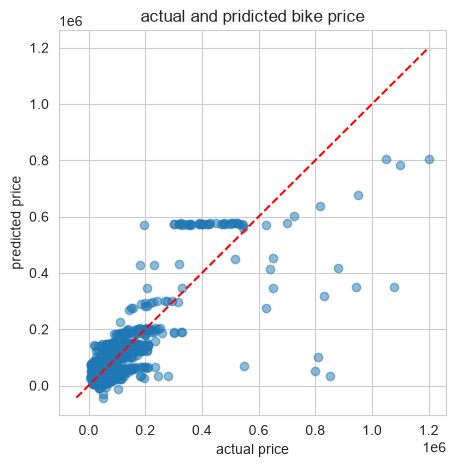

In [74]:
plt.figure(figsize=(5,5,))
plt.scatter(y_test,y_pred,alpha=0.5)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max() , y_pred.max())
plt.plot([min_value , max_value] , [min_value , max_value] , "r--")
plt.xlabel('actual price')
plt.ylabel('predicted price')
plt.title('actual and pridicted bike price')
plt.show()

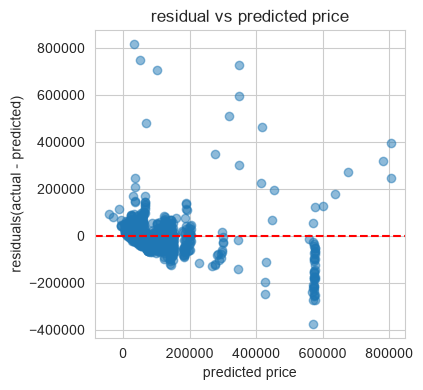

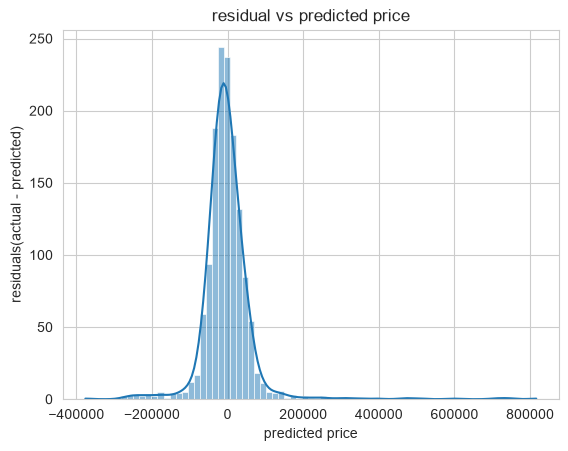

In [75]:
residuals = y_test - y_pred

plt.figure(figsize=(4,4))
plt.scatter(y_pred , residuals , alpha = 0.5)
plt.axhline(0, color = 'red' , linestyle='--')
plt.xlabel('predicted price')
plt.ylabel("residuals(actual - predicted)")
plt.title('residual vs predicted price')
plt.show()

plt.Figure(figsize=(5,5))
sns.histplot(residuals , kde=True)
plt.xlabel('predicted price')
plt.ylabel("residuals(actual - predicted)")
plt.title('residual vs predicted price')
plt.show()

In [76]:
import joblib
joblib.dump(model, 'bike_price_linear_regression.joblib')


['bike_price_linear_regression.joblib']